# Forecast daily sales of Walmart items

LightGBM forecast for the M5 competition. The feature code follows these public Kaggle notebooks:

* https://www.kaggle.com/kernelgenerator/m5-accuracy-tweedie-is-back
* https://www.kaggle.com/kyakovlev/m5-custom-features
* https://www.kaggle.com/kyakovlev/m5-lags-features
* https://www.kaggle.com/kyakovlev/m5-simple-fe

The validation below uses random rows, which overlap in time with training. `backtest/` has the time-based check.

In [ ]:
# run from the project folder so data/ paths work and src/ is importable
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

In [16]:
import gc

import lightgbm as lgb
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

## Build features

In [62]:
from m5_forecasting.features import FeaturePipeline, forecast_columns

pipeline = FeaturePipeline(path="data/raw/", verbose=False)
train = pipeline.build_feature_set()
train.dropna(inplace=True)

In [8]:
categorical_features = [
    "item_id", "dept_id", "store_id", "cat_id", "state_id",
    "event_name_1", "event_name_2", "event_type_1", "event_type_2",
]
excluded_columns = ["id", "date", "sales", "d", "wm_yr_wk", "weekday"]
feature_columns = train.columns[~train.columns.isin(excluded_columns)]

features = train[feature_columns]
target = train["sales"]

# hold out 2M random rows to watch the score while training
valid_rows = np.random.choice(features.index.values, 2_000_000, replace=False)
train_rows = np.setdiff1d(features.index.values, valid_rows)

train_data = lgb.Dataset(
    features.loc[train_rows],
    label=target.loc[train_rows],
    categorical_feature=categorical_features,
    free_raw_data=False,
)
valid_data = lgb.Dataset(
    features.loc[valid_rows],
    label=target.loc[valid_rows],
    categorical_feature=categorical_features,
    free_raw_data=False,
)

del train, features, target, valid_rows, train_rows
gc.collect()

20

In [9]:
params = {
    "objective": "tweedie",
    "tweedie_variance_power": 1.2,
    "metric": "rmse",
    "force_row_wise": True,
    "learning_rate": 0.075,
    "sub_feature": 0.82,
    "sub_row": 0.78,
    "bagging_freq": 1,
    "lambda_l2": 0.1,
    "verbosity": 1,
    "num_iterations": 1250,
    "num_leaves": 128,
    "min_data_in_leaf": 104,
}

In [10]:
%%time

model = lgb.train(
    params, train_data, valid_sets=[valid_data], callbacks=[lgb.log_evaluation(100)]
)
model.save_model("models/forecast/model.lgb")

site-packages\lightgbm\engine.py:148: UserWarning: Found `num_iterations` in params. Will use it instead of argument
  warnings.warn("Found `{}` in params. Will use it instead of argument".format(alias))
site-packages\lightgbm\basic.py:1291: UserWarning: Using categorical_feature in Dataset.
  warnings.warn('Using categorical_feature in Dataset.')


[100]	valid_0's rmse: 2.133
[200]	valid_0's rmse: 2.09867
[300]	valid_0's rmse: 2.0848
[400]	valid_0's rmse: 2.07132
[500]	valid_0's rmse: 2.06237
[600]	valid_0's rmse: 2.05566
[700]	valid_0's rmse: 2.05032
[800]	valid_0's rmse: 2.04547
[900]	valid_0's rmse: 2.04133
[1000]	valid_0's rmse: 2.03749
[1100]	valid_0's rmse: 2.03466
[1200]	valid_0's rmse: 2.03121
Wall time: 45min 28s


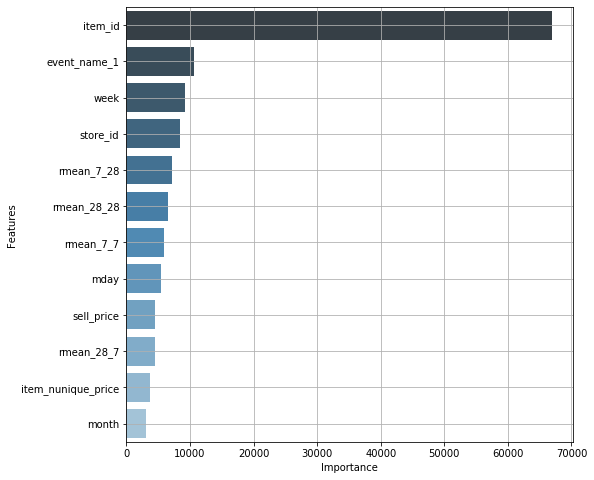

In [41]:
importance = pd.DataFrame(
    {"Features": model.feature_name(), "Importance": model.feature_importance()}
)
importance = importance.sort_values("Importance", ascending=False).head(12)

plt.figure(figsize=(8, 8))
sns.barplot(x="Importance", y="Features", data=importance, palette="Blues_d", orient="h")
plt.grid(True)

In [87]:
%load_ext autoreload
%autoreload 2

test = pipeline.build_test_data()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Forecast sales

In [89]:
%%time

# average three runs with slightly scaled up predictions
multipliers = [1.035, 1.03, 1.025]
weight = 1 / len(multipliers)
day_columns = forecast_columns()

for run, multiplier in enumerate(multipliers):
    # predict one day at a time so later lags use earlier predictions
    for day_offset in range(28):
        day_features, day = pipeline.build_test_features(test, day_offset)
        predictions = model.predict(day_features[feature_columns])
        test.loc[test["date"] == day, "sales"] = multiplier * predictions

    run_submission = pipeline.create_submission(test)
    run_submission.to_csv(f"data/submission/submission_{run}.csv", index=False)

    if run == 0:
        submission = run_submission
        submission[day_columns] *= weight
    else:
        submission[day_columns] += run_submission[day_columns] * weight

# Kaggle also wants the evaluation ids, filled with the same forecast
evaluation = submission.copy()
evaluation["id"] = evaluation["id"].str.replace("validation$", "evaluation", regex=True)
submission = pd.concat([submission, evaluation], axis=0, sort=False)
submission.to_csv("data/submission/submission.csv", index=False)

Wall time: 1h 37min 17s
